<a href="https://colab.research.google.com/github/ShouryaBatra/fbla-data-analysis/blob/main/charts2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

font_path = "/content/Raleway-Regular.ttf"
fm.fontManager.addfont(font_path)
plt.rcParams["font.family"] = "Raleway"

In [20]:
TEXT = "#1B1B1B"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#D0D0D0",
    "axes.labelcolor": TEXT,
    "xtick.color": TEXT,
    "ytick.color": TEXT,
    "text.color": TEXT,
    "font.size": 13,
    "axes.titleweight": "bold",
    "axes.titlesize": 18,
    "axes.labelsize": 14,
})

In [21]:
athletes = pd.read_csv("athlete_events.csv")
nocs = pd.read_csv("noc_regions.csv")

df = athletes.merge(nocs, on="NOC", how="left")
df = df[df["Season"] == "Summer"].copy()
df = df.rename(columns={"region": "Country"})

df["Medal_Won"] = df["Medal"].notna().astype(int)

In [22]:
athletes_by_sport = (
    df.groupby("Sport")["ID"]
    .nunique()
    .reset_index(name="Athletes_Sent")
)

medals_by_sport = (
    df[df["Medal_Won"] == 1]
    .groupby("Sport")["Medal_Won"]
    .sum()
    .reset_index(name="Medals_Won")
)

sport_eff = athletes_by_sport.merge(medals_by_sport, on="Sport", how="left").fillna(0)
sport_eff["Medal_Efficiency"] = sport_eff["Medals_Won"] / sport_eff["Athletes_Sent"]

In [23]:
sport_eff_f = sport_eff[sport_eff["Athletes_Sent"] >= 500]

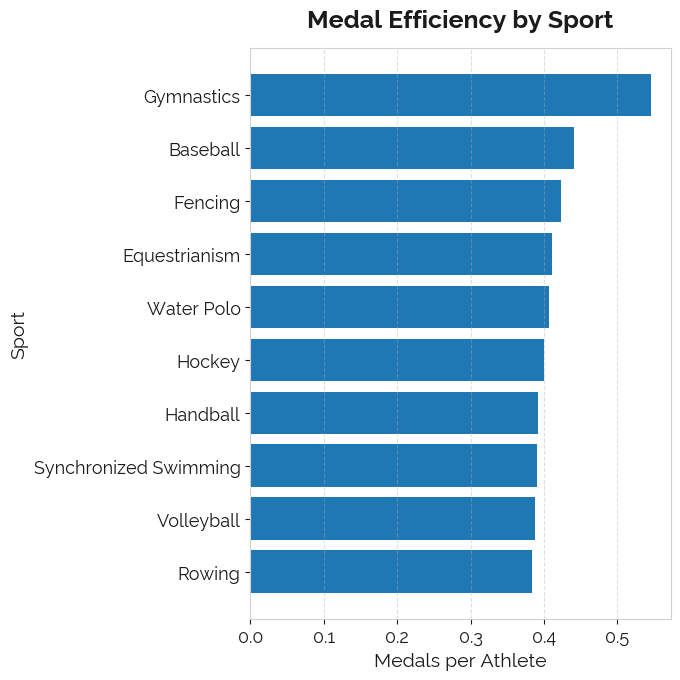

In [24]:
top_eff = (
    sport_eff_f.sort_values("Medal_Efficiency", ascending=True)
    .tail(10)
)

plt.figure(figsize=(7, 7))
plt.barh(top_eff["Sport"], top_eff["Medal_Efficiency"])  # NO color arg

plt.title("Medal Efficiency by Sport", fontsize=18, pad=15)
plt.xlabel("Medals per Athlete", fontsize=14)
plt.ylabel("Sport", fontsize=14)

plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig("chart_medal_efficiency_square.png", dpi=300, bbox_inches="tight")
plt.show()